<a href="https://colab.research.google.com/github/ascot119-rgb/Alex-s-Projects/blob/main/CNN_ResNet_Image_Class.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Standard CNN Network

Using cuda device
Epoch: 1 Loss: 2.096009
Epoch: 2 Loss: 1.9872293
Epoch: 3 Loss: 1.8359982
Epoch: 4 Loss: 1.7552716
Epoch: 5 Loss: 1.6811762
Epoch: 6 Loss: 1.5371821
Epoch: 7 Loss: 1.5801065
Epoch: 8 Loss: 1.4259002
Epoch: 9 Loss: 1.5835053
Epoch: 10 Loss: 1.4613838
Epoch: 11 Loss: 1.4234594
Epoch: 12 Loss: 1.3953795
Epoch: 13 Loss: 1.6143574
Epoch: 14 Loss: 1.3400558
Epoch: 15 Loss: 1.4032891
Epoch: 16 Loss: 1.0234
Epoch: 17 Loss: 1.2017258
Epoch: 18 Loss: 1.291866
Epoch: 19 Loss: 1.3432105
Epoch: 20 Loss: 1.1067764
Epoch: 21 Loss: 1.1579014
Epoch: 22 Loss: 1.2816727
Epoch: 23 Loss: 1.3577331
Epoch: 24 Loss: 1.1544948
Epoch: 25 Loss: 1.1666723
Epoch: 26 Loss: 1.2525648
Epoch: 27 Loss: 0.8410986
Epoch: 28 Loss: 1.1665704
Epoch: 29 Loss: 1.0327597
Epoch: 30 Loss: 1.1039228
Epoch: 31 Loss: 1.1632437
Epoch: 32 Loss: 1.2811683
Epoch: 33 Loss: 1.0857264
Epoch: 34 Loss: 0.8831955
Epoch: 35 Loss: 1.0303475
Epoch: 36 Loss: 1.0902698
Epoch: 37 Loss: 0.95824003
Epoch: 38 Loss: 0.99254644
Epoch:

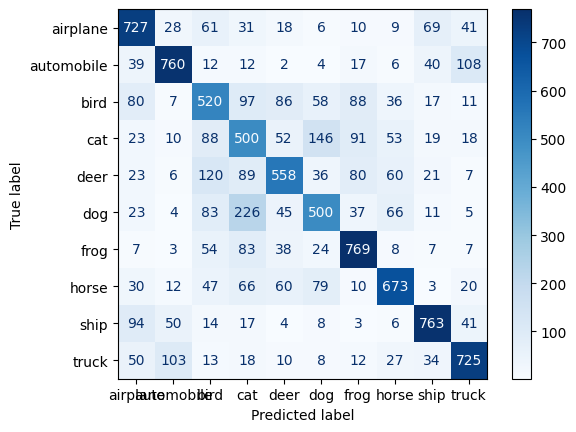

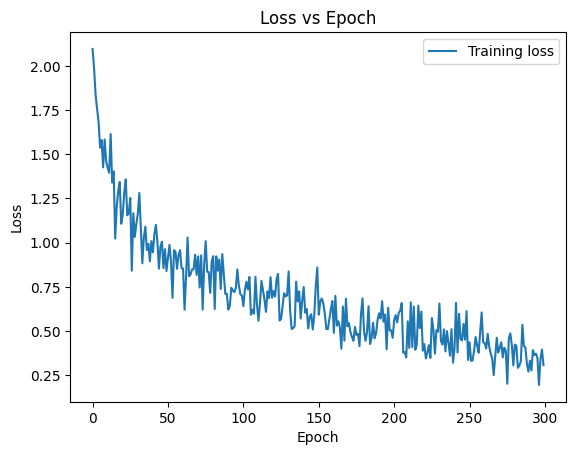

In [ ]:
import sys
import sympy
import sympy.logic
import sympy.logic.boolalg
# Forcefully bind the module into sympy namespace to bypass lazy loading issues
setattr(sympy, 'logic', sys.modules['sympy.logic'])
setattr(sympy, 'core', sys.modules['sympy.core'])

from torch.nn.modules.activation import LogSoftmax
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import time
from sklearn.metrics import precision_score, recall_score

device = pt.device("cuda") if pt.cuda.is_available() else pt.device("cpu")
print(f"Using {device} device")

transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
cifar10 = torchvision.datasets.CIFAR10(root='./data', download=True, transform=transform)
cifar10_val = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

labels = cifar10.targets
labels_val = cifar10_val.targets

class Net(nn.Module):
  def __init__(self):
    super().__init__()
    self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
    self.act1 = nn.Tanh()
    self.pool1 = nn.MaxPool2d(2)
    self.conv2 = nn.Conv2d(16, 12, kernel_size=3, padding=1)
    self.act2 = nn.Tanh()
    self.pool2 = nn.MaxPool2d(2)
    self.fc1 = nn.Linear(12 * 8 * 8, 48)
    self.act3 = nn.Tanh()
    self.fc2 = nn.Linear(48, 10)
  def forward(self, x):
    out = self.pool1(self.act1(self.conv1(x)))
    out = self.pool2(self.act2(self.conv2(out)))
    out = out.view(-1, 12 * 8 * 8)
    out = self.act3(self.fc1(out))
    out = self.fc2(out)
    return out

labels_orig = pt.tensor(labels.copy())

def softmax(x):
  return pt.exp(x) /pt.exp(x).sum()

train_loader = pt.utils.data.DataLoader(cifar10, batch_size=128, shuffle=True, num_workers=2)

train_loader_full = pt.utils.data.DataLoader(cifar10, batch_size=1000, shuffle=False, num_workers=2)
val_loader = pt.utils.data.DataLoader(cifar10_val, batch_size=1000, shuffle=False, num_workers=2)

model = Net().to(device=device)
loss_fn = nn.CrossEntropyLoss()
optimizer = pt.optim.SGD(model.parameters(), lr=0.01)
n_epochs = 300

start_time = time.perf_counter()
loss_over_time = []

for epoch in range(n_epochs):
  model.train()
  for imgs, labels_batch in train_loader:
    imgs, labels = imgs.to(device=device), labels_batch.to(device=device)
    batch_size = imgs.shape[0]
    outputs = model(imgs)
    loss = loss_fn(outputs.to(device=device), labels_batch.to(device=device))
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  loss_over_time.append(loss.detach().tolist())
  print("Epoch:" , epoch + 1, "Loss:", loss.detach().cpu().numpy())

print("Time: " + str(time.perf_counter() - start_time) + " Seconds")

model.eval()
pred_val_list = []
pred_train_list = []

with pt.no_grad():
  for imgs, _ in val_loader:
    outputs = model(imgs.to(device))
    pred_val_list.append(outputs)
  pred_val = pt.cat(pred_val_list, dim=0)
  pred_val = pt.argmax(pred_val, dim=1)

  for imgs, _ in train_loader_full:
    outputs = model(imgs.to(device))
    pred_train_list.append(outputs)
  pred_train = pt.cat(pred_train_list, dim=0)


disp = ConfusionMatrixDisplay.from_predictions(
    np.round(labels_val),
    pred_val.cpu().detach().numpy(),
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize=None,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable Parameters: {trainable_params:,}")

print("Training Loss:", loss_fn(pred_train, labels_orig.to(device)).cpu().detach().numpy())
pred_train = pt.argmax(pred_train, dim=1)
print("Training Accuracy", (pred_train == labels_orig.to(device)).float().mean().item())
print("Validation Accuracy", (pred_val == pt.tensor(labels_val).to(device)).float().mean().item())
print("Validation Precision", precision_score(labels_val, pred_val.cpu(), average="macro"))
print("Validation Recall", recall_score(labels_val, pred_val.cpu(), average="macro"))
plt.figure()
plt.plot(np.arange(len(loss_over_time)), loss_over_time, label="Training loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

Using cuda device
Epoch: 1 Loss: 2.2417433
Epoch: 2 Loss: 2.153932
Epoch: 3 Loss: 1.9418242
Epoch: 4 Loss: 1.8942127
Epoch: 5 Loss: 1.9707543
Epoch: 6 Loss: 1.8628063
Epoch: 7 Loss: 1.738704
Epoch: 8 Loss: 1.6409738
Epoch: 9 Loss: 1.7149723
Epoch: 10 Loss: 1.5094134
Epoch: 11 Loss: 1.4708712
Epoch: 12 Loss: 1.2925906
Epoch: 13 Loss: 1.5315349
Epoch: 14 Loss: 1.2901781
Epoch: 15 Loss: 1.4883417
Epoch: 16 Loss: 1.3277488
Epoch: 17 Loss: 1.412039
Epoch: 18 Loss: 1.2814178
Epoch: 19 Loss: 1.3487039
Epoch: 20 Loss: 1.3416272
Epoch: 21 Loss: 1.0482925
Epoch: 22 Loss: 1.3087276
Epoch: 23 Loss: 1.3533376
Epoch: 24 Loss: 1.1934597
Epoch: 25 Loss: 1.5342405
Epoch: 26 Loss: 1.5931578
Epoch: 27 Loss: 1.0605494
Epoch: 28 Loss: 1.1995198
Epoch: 29 Loss: 1.326061
Epoch: 30 Loss: 1.1353685
Epoch: 31 Loss: 1.0562997
Epoch: 32 Loss: 0.95457107
Epoch: 33 Loss: 1.3161266
Epoch: 34 Loss: 1.0696295
Epoch: 35 Loss: 0.9618826
Epoch: 36 Loss: 1.2270644
Epoch: 37 Loss: 1.0299195
Epoch: 38 Loss: 0.9568707
Epoch:

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78de869ead40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78de869ead40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Trainable Parameters: 18,512
Training Loss: 0.5209092
Training Accuracy 0.8223399519920349
Validation Accuracy 0.7195999622344971
Validation Precision 0.7183723607758601
Validation Recall 0.7196


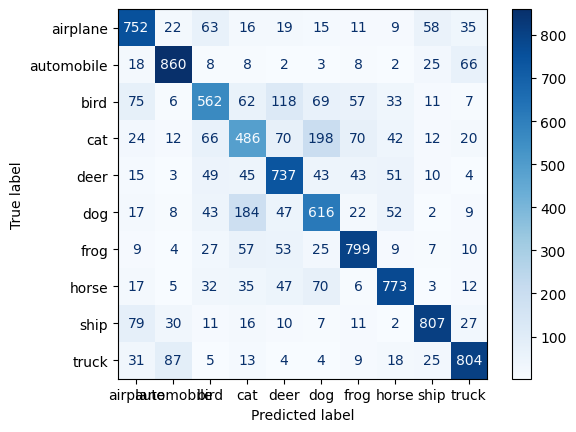

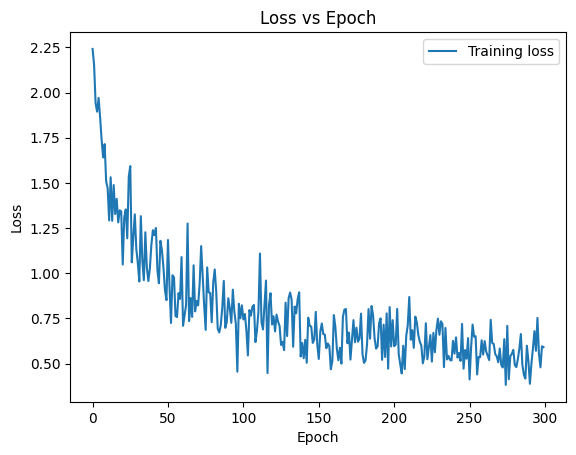

In [ ]:
import sys
import sympy
import sympy.logic
import sympy.logic.boolalg
# Forcefully bind the module into sympy namespace to bypass lazy loading issues
setattr(sympy, 'logic', sys.modules['sympy.logic'])
setattr(sympy, 'core', sys.modules['sympy.core'])

from torch.nn.modules.activation import LogSoftmax
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import time
from sklearn.metrics import precision_score, recall_score

device = pt.device("cuda") if pt.cuda.is_available() else pt.device("cpu")
print(f"Using {device} device")

transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
cifar10 = torchvision.datasets.CIFAR10(root='./data', download=True, transform=transform)
cifar10_val = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

labels = cifar10.targets
labels_val = cifar10_val.targets

class Net(nn.Module):
  def __init__(self):
    super().__init__()
    self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
    self.act1 = nn.Tanh()
    self.pool1 = nn.MaxPool2d(2)
    self.conv2 = nn.Conv2d(16, 12, kernel_size=3, padding=1)
    self.act2 = nn.Tanh()
    self.pool2 = nn.MaxPool2d(2)
    self.conv3 = nn.Conv2d(12, 18, kernel_size=3, padding=1)
    self.act3 = nn.Tanh()
    self.pool3 = nn.MaxPool2d(2)
    self.fc1 = nn.Linear(18 * 4 * 4, 48)
    self.act4 = nn.Tanh()
    self.fc2 = nn.Linear(48, 10)
  def forward(self, x):
    out = self.pool1(self.act1(self.conv1(x)))
    out = self.pool2(self.act2(self.conv2(out)))
    out = self.pool3(self.act3(self.conv3(out)))
    out = out.view(-1, 18 * 4 * 4)
    out = self.act4(self.fc1(out))
    out = self.fc2(out)
    return out

labels_orig = pt.tensor(labels.copy())

def softmax(x):
  return pt.exp(x) /pt.exp(x).sum()

train_loader = pt.utils.data.DataLoader(cifar10, batch_size=128, shuffle=True, num_workers=2)

train_loader_full = pt.utils.data.DataLoader(cifar10, batch_size=1000, shuffle=False, num_workers=2)
val_loader = pt.utils.data.DataLoader(cifar10_val, batch_size=1000, shuffle=False, num_workers=2)

model = Net().to(device=device)
loss_fn = nn.CrossEntropyLoss()
optimizer = pt.optim.SGD(model.parameters(), lr=0.01)
n_epochs = 300

start_time = time.perf_counter()
loss_over_time = []

for epoch in range(n_epochs):
  model.train()
  for imgs, labels_batch in train_loader:
    imgs, labels = imgs.to(device=device), labels_batch.to(device=device)
    batch_size = imgs.shape[0]
    outputs = model(imgs)
    loss = loss_fn(outputs.to(device=device), labels_batch.to(device=device))
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  loss_over_time.append(loss.detach().tolist())
  print("Epoch:" , epoch + 1, "Loss:", loss.detach().cpu().numpy())

print("Time: " + str(time.perf_counter() - start_time) + " Seconds")

model.eval()
pred_val_list = []
pred_train_list = []

with pt.no_grad():
  for imgs, _ in val_loader:
    outputs = model(imgs.to(device))
    pred_val_list.append(outputs)
  pred_val = pt.cat(pred_val_list, dim=0)
  pred_val = pt.argmax(pred_val, dim=1)

  for imgs, _ in train_loader_full:
    outputs = model(imgs.to(device))
    pred_train_list.append(outputs)
  pred_train = pt.cat(pred_train_list, dim=0)


disp = ConfusionMatrixDisplay.from_predictions(
    np.round(labels_val),
    pred_val.cpu().detach().numpy(),
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize=None,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable Parameters: {trainable_params:,}")

print("Training Loss:", loss_fn(pred_train, labels_orig.to(device)).cpu().detach().numpy())
pred_train = pt.argmax(pred_train, dim=1)
print("Training Accuracy", (pred_train == labels_orig.to(device)).float().mean().item())
print("Validation Accuracy", (pred_val == pt.tensor(labels_val).to(device)).float().mean().item())
print("Validation Precision", precision_score(labels_val, pred_val.cpu(), average="macro"))
print("Validation Recall", recall_score(labels_val, pred_val.cpu(), average="macro"))
plt.figure()
plt.plot(np.arange(len(loss_over_time)), loss_over_time, label="Training loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# ResNet Networks

Using cuda device


100%|██████████| 170M/170M [00:06<00:00, 27.6MB/s]


Epoch: 1 Loss: 2.2967105
Epoch: 2 Loss: 2.2714076
Epoch: 3 Loss: 2.1581838
Epoch: 4 Loss: 1.726635
Epoch: 5 Loss: 1.6870441
Epoch: 6 Loss: 1.6310482
Epoch: 7 Loss: 1.4954567
Epoch: 8 Loss: 1.5139431
Epoch: 9 Loss: 1.2458875
Epoch: 10 Loss: 1.625261
Epoch: 11 Loss: 1.3969969
Epoch: 12 Loss: 1.3358605
Epoch: 13 Loss: 1.2680266
Epoch: 14 Loss: 1.1672602
Epoch: 15 Loss: 1.1775717
Epoch: 16 Loss: 1.4135201
Epoch: 17 Loss: 1.1362981
Epoch: 18 Loss: 1.0091963
Epoch: 19 Loss: 0.8826165
Epoch: 20 Loss: 1.0319808
Epoch: 21 Loss: 0.97730273
Epoch: 22 Loss: 0.9495095
Epoch: 23 Loss: 0.7083508
Epoch: 24 Loss: 0.936306
Epoch: 25 Loss: 0.7368546
Epoch: 26 Loss: 0.6561007
Epoch: 27 Loss: 0.8822457
Epoch: 28 Loss: 0.73604167
Epoch: 29 Loss: 0.73132265
Epoch: 30 Loss: 0.6408185
Epoch: 31 Loss: 0.49348336
Epoch: 32 Loss: 0.6446146
Epoch: 33 Loss: 0.66545117
Epoch: 34 Loss: 0.7631469
Epoch: 35 Loss: 0.58516324
Epoch: 36 Loss: 0.7006674
Epoch: 37 Loss: 0.7425692
Epoch: 38 Loss: 0.8811409
Epoch: 39 Loss: 0.

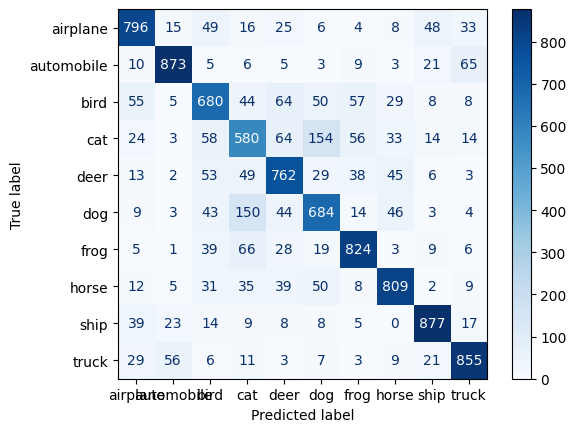

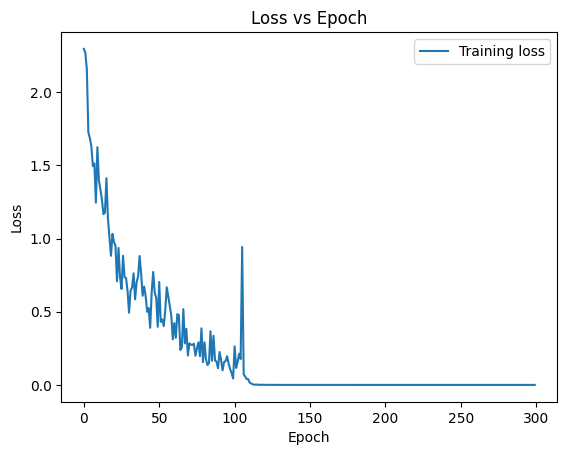

In [ ]:
import sys
import sympy
import sympy.logic
import sympy.logic.boolalg
# Forcefully bind the module into sympy namespace to bypass lazy loading issues
setattr(sympy, 'logic', sys.modules['sympy.logic'])
setattr(sympy, 'core', sys.modules['sympy.core'])

from torch.nn.modules.activation import LogSoftmax
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import torch.nn.functional as f
import time
from sklearn.metrics import precision_score, recall_score

device = pt.device("cuda") if pt.cuda.is_available() else pt.device("cpu")
print(f"Using {device} device")

transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
cifar10 = torchvision.datasets.CIFAR10(root='./data', download=True, transform=transform)
cifar10_val = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

labels = cifar10.targets
labels_val = cifar10_val.targets

class ResNet(nn.Module):
  def __init__(self, netsize=16, netsize2=32):
    super().__init__()
    self.conv1 = nn.Conv2d(3, 64, kernel_size=3, padding=1)
    self.conv2_1 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_2 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_3 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_4 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_5 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_6 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_7 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_8 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv3 = nn.Conv2d(64, 32, kernel_size=3, padding=1)
    self.conv4_1 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_2 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_3 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_4 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_5 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_6 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv5 = nn.Conv2d(32, 16, kernel_size=3, padding=1)
    self.conv6_1 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_2 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_3 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_4 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_5 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_6 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.fc1 = nn.Linear(16 * 4 * 4, 48)
    self.fc2 = nn.Linear(48, 10)
  def forward(self, x):
    out = f.max_pool2d(pt.relu(self.conv1(x)), 2)
    out1 = out
    out = pt.relu(self.conv2_5(pt.relu(self.conv2_1(out))) + out1)
    out1 = out
    out = pt.relu(self.conv2_6(pt.relu(self.conv2_2(out))) + out1)
    out1 = out
    out = pt.relu(self.conv2_7(pt.relu(self.conv2_3(out))) + out1)
    out1 = out
    out = pt.relu(self.conv2_8(pt.relu(self.conv2_4(out))) + out1)
    out = f.max_pool2d(pt.relu(self.conv3(out)), 2)
    out1 = out
    out = pt.relu(self.conv4_4(pt.relu(self.conv4_1(out))) + out1)
    out1 = out
    out = pt.relu(self.conv4_5(pt.relu(self.conv4_2(out))) + out1)
    out1 = out
    out = pt.relu(self.conv4_6(pt.relu(self.conv4_3(out))) + out1)
    out = f.max_pool2d(pt.relu(self.conv5(out)), 2)
    out1 = out
    out = pt.relu(self.conv6_4(pt.relu(self.conv6_1(out))) + out1)
    out1 = out
    out = pt.relu(self.conv6_5(pt.relu(self.conv6_2(out))) + out1)
    out1 = out
    out = pt.relu(self.conv6_6(pt.relu(self.conv6_3(out))) + out1)
    out = out.view(-1, (16 * 4 * 4))
    out = pt.relu(self.fc1(out))
    out = self.fc2(out)
    return out

labels_orig = pt.tensor(labels.copy())

def softmax(x):
  return pt.exp(x) /pt.exp(x).sum()

train_loader = pt.utils.data.DataLoader(cifar10, batch_size=128, shuffle=True, num_workers=2)

train_loader_full = pt.utils.data.DataLoader(cifar10, batch_size=1000, shuffle=False, num_workers=2)
val_loader = pt.utils.data.DataLoader(cifar10_val, batch_size=1000, shuffle=False, num_workers=2)

model = ResNet(netsize=32, netsize2=64).to(device=device)
loss_fn = nn.CrossEntropyLoss()
optimizer = pt.optim.SGD(model.parameters(), lr=0.01)
n_epochs = 300

start_time = time.perf_counter()
loss_over_time = []

for epoch in range(n_epochs):
  model.train()
  for imgs, labels_batch in train_loader:
    imgs, labels = imgs.to(device=device), labels_batch.to(device=device)
    batch_size = imgs.shape[0]
    outputs = model(imgs)
    loss = loss_fn(outputs.to(device=device), labels_batch.to(device=device))
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  loss_over_time.append(loss.detach().tolist())
  print("Epoch:" , epoch + 1, "Loss:", loss.detach().cpu().numpy())

print("Time: " + str(time.perf_counter() - start_time) + " Seconds")

model.eval()
pred_val_list = []
pred_train_list = []

with pt.no_grad():
  for imgs, _ in val_loader:
    outputs = model(imgs.to(device))
    pred_val_list.append(outputs)
  pred_val = pt.cat(pred_val_list, dim=0)
  pred_val = pt.argmax(pred_val, dim=1)

  for imgs, _ in train_loader_full:
    outputs = model(imgs.to(device))
    pred_train_list.append(outputs)
  pred_train = pt.cat(pred_train_list, dim=0)


disp = ConfusionMatrixDisplay.from_predictions(
    np.round(labels_val),
    pred_val.cpu().detach().numpy(),
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize=None,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable Parameters: {trainable_params:,}")

print("Training Loss:", loss_fn(pred_train, labels_orig.to(device)).cpu().detach().numpy())
pred_train = pt.argmax(pred_train, dim=1)
print("Training Accuracy", (pred_train == labels_orig.to(device)).float().mean().item())
print("Validation Accuracy", (pred_val == pt.tensor(labels_val).to(device)).float().mean().item())
print("Validation Precision", precision_score(labels_val, pred_val.cpu(), average="macro"))
print("Validation Recall", recall_score(labels_val, pred_val.cpu(), average="macro"))
plt.figure()
plt.plot(np.arange(len(loss_over_time)), loss_over_time, label="Training loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

Using cuda device


100%|██████████| 170M/170M [05:39<00:00, 502kB/s]


Epoch: 1 Loss: 2.2705033
Epoch: 2 Loss: 1.8703907
Epoch: 3 Loss: 1.6945953
Epoch: 4 Loss: 1.6801224
Epoch: 5 Loss: 1.5110378
Epoch: 6 Loss: 1.5243185
Epoch: 7 Loss: 1.3677428
Epoch: 8 Loss: 1.3259151
Epoch: 9 Loss: 1.4396331
Epoch: 10 Loss: 1.3496273
Epoch: 11 Loss: 1.2645481
Epoch: 12 Loss: 1.3795487
Epoch: 13 Loss: 1.1993592
Epoch: 14 Loss: 1.2099961
Epoch: 15 Loss: 1.0569919
Epoch: 16 Loss: 1.1206748
Epoch: 17 Loss: 1.1842823
Epoch: 18 Loss: 0.89895934
Epoch: 19 Loss: 0.9962966
Epoch: 20 Loss: 0.88454723
Epoch: 21 Loss: 0.71198744
Epoch: 22 Loss: 0.96560735
Epoch: 23 Loss: 0.9366867
Epoch: 24 Loss: 0.96513593
Epoch: 25 Loss: 0.89369327
Epoch: 26 Loss: 0.6905384
Epoch: 27 Loss: 0.81653965
Epoch: 28 Loss: 0.72445357
Epoch: 29 Loss: 0.93147486
Epoch: 30 Loss: 1.0446254
Epoch: 31 Loss: 0.63984823
Epoch: 32 Loss: 0.78130865
Epoch: 33 Loss: 0.7836094
Epoch: 34 Loss: 0.8018135
Epoch: 35 Loss: 0.7949046
Epoch: 36 Loss: 0.8985674
Epoch: 37 Loss: 0.720039
Epoch: 38 Loss: 0.6557711
Epoch: 39 L

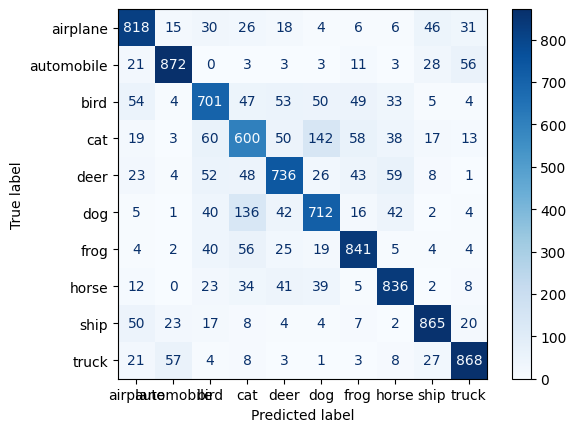

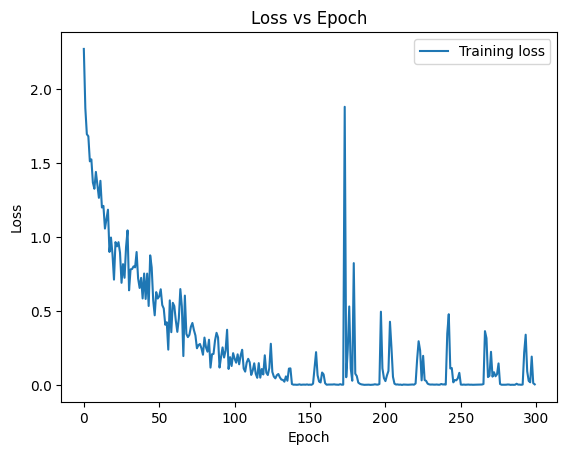

In [ ]:
import sys
import sympy
import sympy.logic
import sympy.logic.boolalg
# Forcefully bind the module into sympy namespace to bypass lazy loading issues
setattr(sympy, 'logic', sys.modules['sympy.logic'])
setattr(sympy, 'core', sys.modules['sympy.core'])

from torch.nn.modules.activation import LogSoftmax
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import torch.nn.functional as f
import time
from sklearn.metrics import precision_score, recall_score

device = pt.device("cuda") if pt.cuda.is_available() else pt.device("cpu")
print(f"Using {device} device")

transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
cifar10 = torchvision.datasets.CIFAR10(root='./data', download=True, transform=transform)
cifar10_val = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

labels = cifar10.targets
labels_val = cifar10_val.targets

class ResNet(nn.Module):
  def __init__(self, netsize=16, netsize2=32):
    super().__init__()
    self.conv1 = nn.Conv2d(3, 64, kernel_size=3, padding=1)
    self.conv2_1 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_2 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_3 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_4 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_5 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_6 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_7 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_8 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv3 = nn.Conv2d(64, 32, kernel_size=3, padding=1)
    self.conv4_1 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_2 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_3 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_4 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_5 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_6 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv5 = nn.Conv2d(32, 16, kernel_size=3, padding=1)
    self.conv6_1 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_2 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_3 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_4 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_5 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_6 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.fc1 = nn.Linear(16 * 4 * 4, 48)
    self.fc2 = nn.Linear(48, 10)
  def forward(self, x):
    out = f.max_pool2d(pt.relu(self.conv1(x)), 2)
    out1 = out
    out = pt.relu(self.conv2_5(pt.relu(self.conv2_1(out))) + out1)
    out1 = out
    out = pt.relu(self.conv2_6(pt.relu(self.conv2_2(out))) + out1)
    out1 = out
    out = pt.relu(self.conv2_7(pt.relu(self.conv2_3(out))) + out1)
    out1 = out
    out = pt.relu(self.conv2_8(pt.relu(self.conv2_4(out))) + out1)
    out = f.max_pool2d(pt.relu(self.conv3(out)), 2)
    out1 = out
    out = pt.relu(self.conv4_4(pt.relu(self.conv4_1(out))) + out1)
    out1 = out
    out = pt.relu(self.conv4_5(pt.relu(self.conv4_2(out))) + out1)
    out1 = out
    out = pt.relu(self.conv4_6(pt.relu(self.conv4_3(out))) + out1)
    out = f.max_pool2d(pt.relu(self.conv5(out)), 2)
    out1 = out
    out = pt.relu(self.conv6_4(pt.relu(self.conv6_1(out))) + out1)
    out1 = out
    out = pt.relu(self.conv6_5(pt.relu(self.conv6_2(out))) + out1)
    out1 = out
    out = pt.relu(self.conv6_6(pt.relu(self.conv6_3(out))) + out1)
    out = out.view(-1, (16 * 4 * 4))
    out = pt.relu(self.fc1(out))
    out = self.fc2(out)
    return out

labels_orig = pt.tensor(labels.copy())

def softmax(x):
  return pt.exp(x) /pt.exp(x).sum()

train_loader = pt.utils.data.DataLoader(cifar10, batch_size=128, shuffle=True, num_workers=2)

train_loader_full = pt.utils.data.DataLoader(cifar10, batch_size=1000, shuffle=False, num_workers=2)
val_loader = pt.utils.data.DataLoader(cifar10_val, batch_size=1000, shuffle=False, num_workers=2)

model = ResNet(netsize=32, netsize2=64).to(device=device)
loss_fn = nn.CrossEntropyLoss()
optimizer = pt.optim.SGD(model.parameters(), lr=0.01, weight_decay=0.001)
n_epochs = 300

start_time = time.perf_counter()
loss_over_time = []

for epoch in range(n_epochs):
  model.train()
  for imgs, labels_batch in train_loader:
    imgs, labels = imgs.to(device=device), labels_batch.to(device=device)
    batch_size = imgs.shape[0]
    outputs = model(imgs)
    loss = loss_fn(outputs.to(device=device), labels_batch.to(device=device))
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  loss_over_time.append(loss.detach().tolist())
  print("Epoch:" , epoch + 1, "Loss:", loss.detach().cpu().numpy())

print("Time: " + str(time.perf_counter() - start_time) + " Seconds")

model.eval()
pred_val_list = []
pred_train_list = []

with pt.no_grad():
  for imgs, _ in val_loader:
    outputs = model(imgs.to(device))
    pred_val_list.append(outputs)
  pred_val = pt.cat(pred_val_list, dim=0)
  pred_val = pt.argmax(pred_val, dim=1)

  for imgs, _ in train_loader_full:
    outputs = model(imgs.to(device))
    pred_train_list.append(outputs)
  pred_train = pt.cat(pred_train_list, dim=0)


disp = ConfusionMatrixDisplay.from_predictions(
    np.round(labels_val),
    pred_val.cpu().detach().numpy(),
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize=None,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable Parameters: {trainable_params:,}")

print("Training Loss:", loss_fn(pred_train, labels_orig.to(device)).cpu().detach().numpy())
pred_train = pt.argmax(pred_train, dim=1)
print("Training Accuracy", (pred_train == labels_orig.to(device)).float().mean().item())
print("Validation Accuracy", (pred_val == pt.tensor(labels_val).to(device)).float().mean().item())
print("Validation Precision", precision_score(labels_val, pred_val.cpu(), average="macro"))
print("Validation Recall", recall_score(labels_val, pred_val.cpu(), average="macro"))
plt.figure()
plt.plot(np.arange(len(loss_over_time)), loss_over_time, label="Training loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

Using cuda device


100%|██████████| 170M/170M [29:44<00:00, 95.6kB/s]


Epoch: 1 Loss: 2.3000686
Epoch: 2 Loss: 2.207705
Epoch: 3 Loss: 1.8400784
Epoch: 4 Loss: 1.8126198
Epoch: 5 Loss: 1.7772354
Epoch: 6 Loss: 1.5626023
Epoch: 7 Loss: 1.7122469
Epoch: 8 Loss: 1.4281147
Epoch: 9 Loss: 1.4534253
Epoch: 10 Loss: 1.2986395
Epoch: 11 Loss: 1.1976125
Epoch: 12 Loss: 1.3188437
Epoch: 13 Loss: 1.3731428
Epoch: 14 Loss: 1.223751
Epoch: 15 Loss: 1.0701851
Epoch: 16 Loss: 1.3515015
Epoch: 17 Loss: 1.0461845
Epoch: 18 Loss: 1.2321312
Epoch: 19 Loss: 1.0216296
Epoch: 20 Loss: 1.1879126
Epoch: 21 Loss: 0.9726555
Epoch: 22 Loss: 0.8361052
Epoch: 23 Loss: 0.86913097
Epoch: 24 Loss: 1.0549262
Epoch: 25 Loss: 0.82870644
Epoch: 26 Loss: 0.819726
Epoch: 27 Loss: 1.1074994
Epoch: 28 Loss: 0.7288397
Epoch: 29 Loss: 0.9647953
Epoch: 30 Loss: 0.7825659
Epoch: 31 Loss: 0.8628891
Epoch: 32 Loss: 0.910426
Epoch: 33 Loss: 0.8497216
Epoch: 34 Loss: 0.7963308
Epoch: 35 Loss: 0.713172
Epoch: 36 Loss: 0.7043129
Epoch: 37 Loss: 0.76634395
Epoch: 38 Loss: 0.64008266
Epoch: 39 Loss: 0.9447

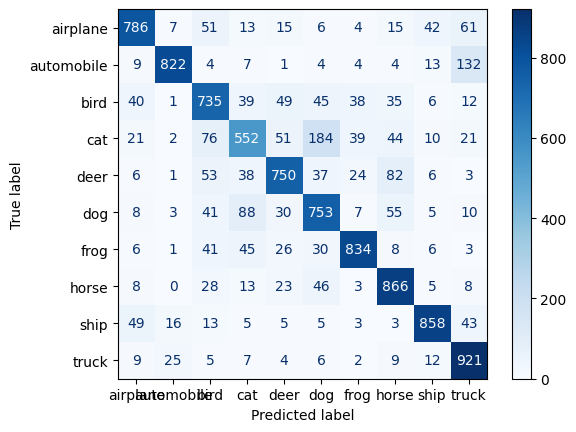

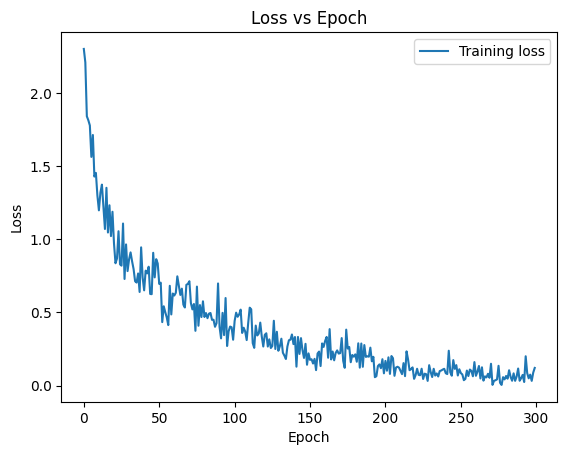

In [ ]:
import sys
import sympy
import sympy.logic
import sympy.logic.boolalg
# Forcefully bind the module into sympy namespace to bypass lazy loading issues
setattr(sympy, 'logic', sys.modules['sympy.logic'])
setattr(sympy, 'core', sys.modules['sympy.core'])

from torch.nn.modules.activation import LogSoftmax
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import torch.nn.functional as f
import time
from sklearn.metrics import precision_score, recall_score

device = pt.device("cuda") if pt.cuda.is_available() else pt.device("cpu")
print(f"Using {device} device")

transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
cifar10 = torchvision.datasets.CIFAR10(root='./data', download=True, transform=transform)
cifar10_val = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

labels = cifar10.targets
labels_val = cifar10_val.targets

class ResNet(nn.Module):
  def __init__(self, netsize=16, netsize2=32):
    super().__init__()
    self.dropout = nn.Dropout2d(0.3)
    self.conv1 = nn.Conv2d(3, 64, kernel_size=3, padding=1)
    self.conv2_1 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_2 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_3 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_4 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_5 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_6 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_7 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_8 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv3 = nn.Conv2d(64, 32, kernel_size=3, padding=1)
    self.conv4_1 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_2 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_3 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_4 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_5 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_6 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv5 = nn.Conv2d(32, 16, kernel_size=3, padding=1)
    self.conv6_1 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_2 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_3 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_4 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_5 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_6 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.fc1 = nn.Linear(16 * 4 * 4, 48)
    self.fc2 = nn.Linear(48, 10)
  def block(self, fun1, fun2, add):
    return pt.relu(fun2(self.dropout(pt.relu(fun1(add)))) + add)
  def forward(self, x):
    out = f.max_pool2d(pt.relu(self.conv1(x)), 2)
    out = self.block(self.conv2_1, self.conv2_5, out)
    out = self.block(self.conv2_2, self.conv2_6, out)
    out = self.block(self.conv2_3, self.conv2_7, out)
    out = self.block(self.conv2_4, self.conv2_8, out)
    out = f.max_pool2d(pt.relu(self.conv3(out)), 2)
    out = self.block(self.conv4_1, self.conv4_4, out)
    out = self.block(self.conv4_2, self.conv4_5, out)
    out = self.block(self.conv4_3, self.conv4_6, out)
    out = f.max_pool2d(pt.relu(self.conv5(out)), 2)
    out = self.block(self.conv6_1, self.conv6_4, out)
    out = self.block(self.conv6_2, self.conv6_5, out)
    out = self.block(self.conv6_3, self.conv6_6, out)
    out = out.view(-1, (16 * 4 * 4))
    out = pt.relu(self.fc1(out))
    out = self.fc2(out)
    return out

labels_orig = pt.tensor(labels.copy())

def softmax(x):
  return pt.exp(x) /pt.exp(x).sum()

train_loader = pt.utils.data.DataLoader(cifar10, batch_size=128, shuffle=True, num_workers=2)

train_loader_full = pt.utils.data.DataLoader(cifar10, batch_size=1000, shuffle=False, num_workers=2)
val_loader = pt.utils.data.DataLoader(cifar10_val, batch_size=1000, shuffle=False, num_workers=2)

model = ResNet(netsize=32, netsize2=64).to(device=device)
loss_fn = nn.CrossEntropyLoss()
optimizer = pt.optim.SGD(model.parameters(), lr=0.01)
n_epochs = 300

start_time = time.perf_counter()
loss_over_time = []

for epoch in range(n_epochs):
  model.train()
  for imgs, labels_batch in train_loader:
    imgs, labels = imgs.to(device=device), labels_batch.to(device=device)
    batch_size = imgs.shape[0]
    outputs = model(imgs)
    loss = loss_fn(outputs.to(device=device), labels_batch.to(device=device))
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  loss_over_time.append(loss.detach().tolist())
  print("Epoch:" , epoch + 1, "Loss:", loss.detach().cpu().numpy())

print("Time: " + str(time.perf_counter() - start_time) + " Seconds")

model.eval()
pred_val_list = []
pred_train_list = []

with pt.no_grad():
  for imgs, _ in val_loader:
    outputs = model(imgs.to(device))
    pred_val_list.append(outputs)
  pred_val = pt.cat(pred_val_list, dim=0)
  pred_val = pt.argmax(pred_val, dim=1)

  for imgs, _ in train_loader_full:
    outputs = model(imgs.to(device))
    pred_train_list.append(outputs)
  pred_train = pt.cat(pred_train_list, dim=0)


disp = ConfusionMatrixDisplay.from_predictions(
    np.round(labels_val),
    pred_val.cpu().detach().numpy(),
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize=None,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable Parameters: {trainable_params:,}")

print("Training Loss:", loss_fn(pred_train, labels_orig.to(device)).cpu().detach().numpy())
pred_train = pt.argmax(pred_train, dim=1)
print("Training Accuracy", (pred_train == labels_orig.to(device)).float().mean().item())
print("Validation Accuracy", (pred_val == pt.tensor(labels_val).to(device)).float().mean().item())
print("Validation Precision", precision_score(labels_val, pred_val.cpu(), average="macro"))
print("Validation Recall", recall_score(labels_val, pred_val.cpu(), average="macro"))
plt.figure()
plt.plot(np.arange(len(loss_over_time)), loss_over_time, label="Training loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

Using cuda device


100%|██████████| 170M/170M [00:15<00:00, 11.1MB/s]


Epoch: 1 Loss: 1.2859596
Epoch: 2 Loss: 1.0225288
Epoch: 3 Loss: 0.95492536
Epoch: 4 Loss: 0.7361786
Epoch: 5 Loss: 0.92603934
Epoch: 6 Loss: 0.562158
Epoch: 7 Loss: 0.5704906
Epoch: 8 Loss: 0.7527067
Epoch: 9 Loss: 0.58035666
Epoch: 10 Loss: 0.6296936
Epoch: 11 Loss: 0.49707404
Epoch: 12 Loss: 0.3085443
Epoch: 13 Loss: 0.49211463
Epoch: 14 Loss: 0.38430136
Epoch: 15 Loss: 0.39902934
Epoch: 16 Loss: 0.33907554
Epoch: 17 Loss: 0.22782376
Epoch: 18 Loss: 0.25441924
Epoch: 19 Loss: 0.29250684
Epoch: 20 Loss: 0.28858116
Epoch: 21 Loss: 0.37543154
Epoch: 22 Loss: 0.2887884
Epoch: 23 Loss: 0.17815025
Epoch: 24 Loss: 0.2009981
Epoch: 25 Loss: 0.20103493
Epoch: 26 Loss: 0.12217377
Epoch: 27 Loss: 0.20472924
Epoch: 28 Loss: 0.17223406
Epoch: 29 Loss: 0.099926114
Epoch: 30 Loss: 0.14164294
Epoch: 31 Loss: 0.10183027
Epoch: 32 Loss: 0.25603664
Epoch: 33 Loss: 0.08866455
Epoch: 34 Loss: 0.034116305
Epoch: 35 Loss: 0.05296583
Epoch: 36 Loss: 0.08711128
Epoch: 37 Loss: 0.074283056
Epoch: 38 Loss: 0.

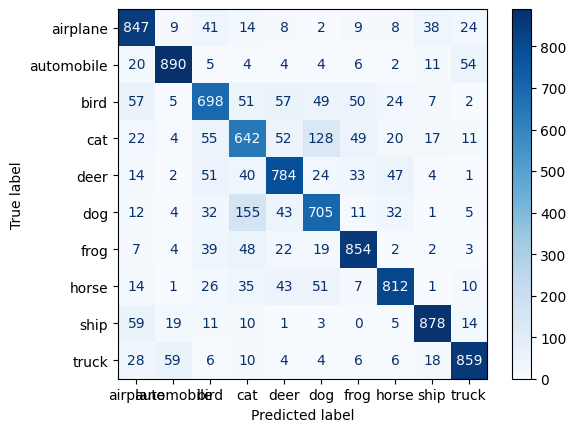

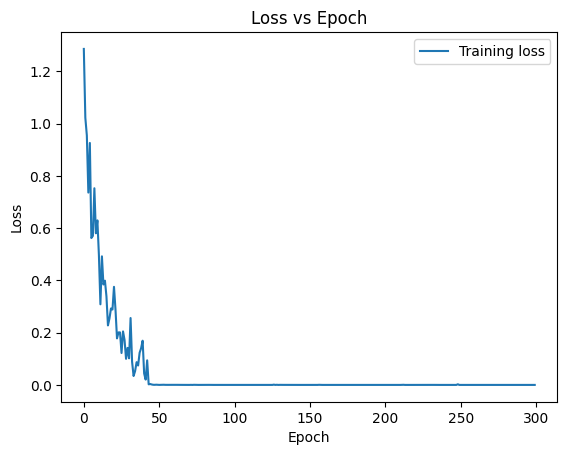

In [1]:
import sys
import sympy
import sympy.logic
import sympy.logic.boolalg
# Forcefully bind the module into sympy namespace to bypass lazy loading issues
setattr(sympy, 'logic', sys.modules['sympy.logic'])
setattr(sympy, 'core', sys.modules['sympy.core'])

from torch.nn.modules.activation import LogSoftmax
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import torch.nn.functional as f
import time
from sklearn.metrics import precision_score, recall_score

device = pt.device("cuda") if pt.cuda.is_available() else pt.device("cpu")
print(f"Using {device} device")

transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
cifar10 = torchvision.datasets.CIFAR10(root='./data', download=True, transform=transform)
cifar10_val = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

labels = cifar10.targets
labels_val = cifar10_val.targets

class ResNet(nn.Module):
  def __init__(self, netsize=16, netsize2=32):
    super().__init__()
    self.dropout = nn.Dropout2d(0.3)
    self.conv1 = nn.Conv2d(3, 64, kernel_size=3, padding=1)
    self.conv2_1 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_2 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_3 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_4 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_5 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_6 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_7 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_8 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.conv2_1_batch=nn.BatchNorm2d(64)
    self.conv2_2_batch=nn.BatchNorm2d(64)
    self.conv2_3_batch=nn.BatchNorm2d(64)
    self.conv2_4_batch=nn.BatchNorm2d(64)
    self.conv2_5_batch=nn.BatchNorm2d(64)
    self.conv2_6_batch=nn.BatchNorm2d(64)
    self.conv2_7_batch=nn.BatchNorm2d(64)
    self.conv2_8_batch=nn.BatchNorm2d(64)
    self.conv3 = nn.Conv2d(64, 32, kernel_size=3, padding=1)
    self.conv4_1 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_2 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_3 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_4 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_5 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_6 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
    self.conv4_1_batch=nn.BatchNorm2d(32)
    self.conv4_2_batch=nn.BatchNorm2d(32)
    self.conv4_3_batch=nn.BatchNorm2d(32)
    self.conv4_4_batch=nn.BatchNorm2d(32)
    self.conv4_5_batch=nn.BatchNorm2d(32)
    self.conv4_6_batch=nn.BatchNorm2d(32)
    self.conv5 = nn.Conv2d(32, 16, kernel_size=3, padding=1)
    self.conv6_1 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_2 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_3 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_4 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_5 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_6 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
    self.conv6_1_batch=nn.BatchNorm2d(16)
    self.conv6_2_batch=nn.BatchNorm2d(16)
    self.conv6_3_batch=nn.BatchNorm2d(16)
    self.conv6_4_batch=nn.BatchNorm2d(16)
    self.conv6_5_batch=nn.BatchNorm2d(16)
    self.conv6_6_batch=nn.BatchNorm2d(16)
    self.fc1 = nn.Linear(16 * 4 * 4, 48)
    self.fc2 = nn.Linear(48, 10)
  def block(self, fun1, fun2, batch_norm_1, batch_norm_2, add):
    return pt.relu(batch_norm_2(fun2(pt.relu(batch_norm_1(fun1(add))))) + add)
  def forward(self, x):
    out = f.max_pool2d(pt.relu(self.conv1(x)), 2)
    out = self.block(self.conv2_1, self.conv2_5, self.conv2_1_batch, self.conv2_5_batch, out)
    out = self.block(self.conv2_2, self.conv2_6, self.conv2_2_batch, self.conv2_6_batch, out)
    out = self.block(self.conv2_3, self.conv2_7, self.conv2_3_batch, self.conv2_7_batch, out)
    out = self.block(self.conv2_4, self.conv2_8, self.conv2_4_batch, self.conv2_8_batch, out)
    out = f.max_pool2d(pt.relu(self.conv3(out)), 2)
    out = self.block(self.conv4_1, self.conv4_4, self.conv4_1_batch, self.conv4_4_batch, out)
    out = self.block(self.conv4_2, self.conv4_5, self.conv4_2_batch, self.conv4_5_batch, out)
    out = self.block(self.conv4_3, self.conv4_6, self.conv4_3_batch, self.conv4_6_batch, out)
    out = f.max_pool2d(pt.relu(self.conv5(out)), 2)
    out = self.block(self.conv6_1, self.conv6_4, self.conv6_1_batch, self.conv6_4_batch, out)
    out = self.block(self.conv6_2, self.conv6_5, self.conv6_2_batch, self.conv6_5_batch, out)
    out = self.block(self.conv6_3, self.conv6_6, self.conv6_3_batch, self.conv6_6_batch, out)
    out = out.view(-1, (16 * 4 * 4))
    out = pt.relu(self.fc1(out))
    out = self.fc2(out)
    return out

labels_orig = pt.tensor(labels.copy())

def softmax(x):
  return pt.exp(x) /pt.exp(x).sum()

train_loader = pt.utils.data.DataLoader(cifar10, batch_size=128, shuffle=True, num_workers=2)

train_loader_full = pt.utils.data.DataLoader(cifar10, batch_size=1000, shuffle=False, num_workers=2)
val_loader = pt.utils.data.DataLoader(cifar10_val, batch_size=1000, shuffle=False, num_workers=2)

model = ResNet(netsize=32, netsize2=64).to(device=device)
loss_fn = nn.CrossEntropyLoss()
optimizer = pt.optim.SGD(model.parameters(), lr=0.01)
n_epochs = 300

start_time = time.perf_counter()
loss_over_time = []

for epoch in range(n_epochs):
  model.train()
  for imgs, labels_batch in train_loader:
    imgs, labels = imgs.to(device=device), labels_batch.to(device=device)
    batch_size = imgs.shape[0]
    outputs = model(imgs)
    loss = loss_fn(outputs.to(device=device), labels_batch.to(device=device))
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  loss_over_time.append(loss.detach().tolist())
  print("Epoch:" , epoch + 1, "Loss:", loss.detach().cpu().numpy())

print("Time: " + str(time.perf_counter() - start_time) + " Seconds")

model.eval()
pred_val_list = []
pred_train_list = []

with pt.no_grad():
  for imgs, _ in val_loader:
    outputs = model(imgs.to(device))
    pred_val_list.append(outputs)
  pred_val = pt.cat(pred_val_list, dim=0)
  pred_val = pt.argmax(pred_val, dim=1)

  for imgs, _ in train_loader_full:
    outputs = model(imgs.to(device))
    pred_train_list.append(outputs)
  pred_train = pt.cat(pred_train_list, dim=0)


disp = ConfusionMatrixDisplay.from_predictions(
    np.round(labels_val),
    pred_val.cpu().detach().numpy(),
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize=None,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable Parameters: {trainable_params:,}")

print("Training Loss:", loss_fn(pred_train, labels_orig.to(device)).cpu().detach().numpy())
pred_train = pt.argmax(pred_train, dim=1)
print("Training Accuracy", (pred_train == labels_orig.to(device)).float().mean().item())
print("Validation Accuracy", (pred_val == pt.tensor(labels_val).to(device)).float().mean().item())
print("Validation Precision", precision_score(labels_val, pred_val.cpu(), average="macro"))
print("Validation Recall", recall_score(labels_val, pred_val.cpu(), average="macro"))
plt.figure()
plt.plot(np.arange(len(loss_over_time)), loss_over_time, label="Training loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()